# Clustering: how do the training and test molecules relate? (exploratory)

**Goal:**
1. Cluster all unique molecules (HOPV + SQL + Kaggle test, when available) on their RDKit descriptors
2. See which training molecules sit in the same clusters as the Kaggle test molecules
3. Export the cluster assignments

This analysis was exploratory: the final models in notebooks 03-06 do **not** use the clusters or sample weights.

---

> **About the outputs:** the outputs shown are from the original run on the course data (the course copy of HOPV, the course SQL molecules, the Kaggle test molecules). The code was refactored afterwards to load data through `src/` and to skip the course-only parts when those files are missing (see `data/README.md`).

## 1. Import Libraries

In [2]:
import sys
sys.path.append("..")

import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

from src.data import PROCESSED_DIR, load_hopv_table, load_kaggle_test, load_sql_molecules
from src.features import DESCRIPTOR_NAMES, compute_all_descriptors

warnings.filterwarnings('ignore')

## 2. Load All Datasets

In [3]:
# HOPV (public) plus the course datasets when they are available
hopv_df = load_hopv_table()
print(f"HOPV: {len(hopv_df)} molecules")

sql_df = load_sql_molecules()
print(f"SQL: {len(sql_df)} molecules" if sql_df is not None else "SQL: not available")

kaggle_class_df = load_kaggle_test("classification")
HAS_KAGGLE = kaggle_class_df is not None
print(f"Kaggle classification: {len(kaggle_class_df)} molecules" if HAS_KAGGLE else "Kaggle test set: not available")

HOPV: 347 molecules
SQL: 232 molecules
Kaggle classification: 200 molecules
Kaggle regression: 200 molecules


## 3. Extract SMILES and Create Combined Dataset

In [4]:
# Create source labels and combine
sources = [pd.DataFrame({'smiles': hopv_df['smiles'].values, 'source': 'HOPV'})]
if sql_df is not None:
    sources.append(pd.DataFrame({'smiles': sql_df['smiles'].values, 'source': 'SQL'}))
if HAS_KAGGLE:
    sources.append(pd.DataFrame({'smiles': kaggle_class_df['smiles'].values, 'source': 'Kaggle'}))
all_molecules = pd.concat(sources, ignore_index=True)

# Get unique molecules
all_molecules_unique = all_molecules.drop_duplicates(subset='smiles', keep='first')

print(f"\nTotal molecules: {len(all_molecules)}")
print(f"Unique molecules: {len(all_molecules_unique)}")
print(f"\nBreakdown by source:")
print(all_molecules_unique['source'].value_counts())


Total molecules: 779
Unique molecules: 779

Breakdown by source:
source
HOPV      347
SQL       232
Kaggle    200
Name: count, dtype: int64


## 4. Compute Molecular Descriptors for All Molecules

This may take a few minutes...

In [5]:
# Shared descriptor code: src/features.py
all_desc_names = DESCRIPTOR_NAMES

print(f"Computing {len(all_desc_names)} descriptors for {len(all_molecules_unique)} molecules...")
print("This will take a few minutes...\n")

# Compute descriptors
descriptors_list = [compute_all_descriptors(s) for s in all_molecules_unique['smiles']]
descriptors_df = pd.DataFrame(descriptors_list)

print(f"Descriptors computed: {descriptors_df.shape}")
print(f"Missing values: {descriptors_df.isna().sum().sum()}")

Computing 217 descriptors for 779 molecules...
This will take a few minutes...

Descriptors computed: (779, 217)
Missing values: 1380


## 5. Preprocess Descriptors

In [6]:
# Handle infinities
descriptors_df = descriptors_df.replace([np.inf, -np.inf], np.nan)

# Remove columns with >50% missing
missing_pct = descriptors_df.isna().mean()
valid_cols = missing_pct[missing_pct < 0.5].index.tolist()
descriptors_df = descriptors_df[valid_cols]
print(f"After removing high-missing columns: {descriptors_df.shape[1]} features")

# Remove constant columns
std_vals = descriptors_df.std()
non_constant_cols = std_vals[std_vals > 0].index.tolist()
descriptors_df = descriptors_df[non_constant_cols]
print(f"After removing constant columns: {descriptors_df.shape[1]} features")

# Fill remaining missing values with median
descriptors_df = descriptors_df.fillna(descriptors_df.median())
print(f"Missing values after imputation: {descriptors_df.isna().sum().sum()}")

After removing high-missing columns: 217 features
After removing constant columns: 176 features
Missing values after imputation: 0


In [7]:
# Standardize features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(descriptors_df)

print(f"\nFinal feature matrix shape: {X_scaled.shape}")
print(f"Ready for clustering!")


Final feature matrix shape: (779, 176)
Ready for clustering!


## 6. Perform Clustering

We'll use **K-Means** with an optimal number of clusters

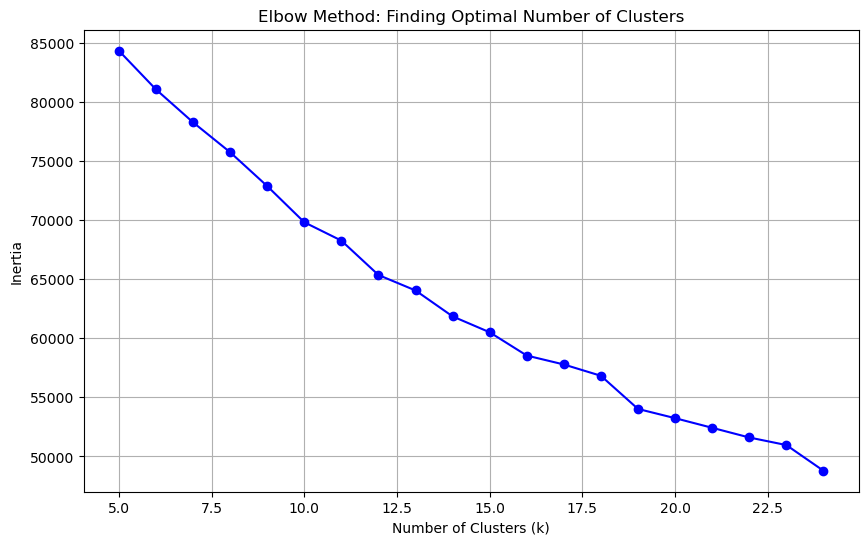

Look for the 'elbow' in the curve above to determine optimal k


In [8]:
# Test different numbers of clusters using elbow method
inertias = []
K_range = range(5, 25)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    inertias.append(kmeans.inertia_)

# Plot elbow curve
plt.figure(figsize=(10, 6))
plt.plot(K_range, inertias, 'bo-')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Inertia')
plt.title('Elbow Method: Finding Optimal Number of Clusters')
plt.grid(True)
plt.show()

print("Look for the 'elbow' in the curve above to determine optimal k")

In [9]:
# Choose optimal k (adjust based on elbow plot)
optimal_k = 12  # Adjust this based on your elbow plot

print(f"Clustering with k={optimal_k}...")
kmeans_final = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
cluster_labels = kmeans_final.fit_predict(X_scaled)

# Add to dataframe
all_molecules_unique['cluster_id'] = cluster_labels

print(f"\nCluster distribution:")
print(all_molecules_unique['cluster_id'].value_counts().sort_index())

Clustering with k=12...

Cluster distribution:
cluster_id
0      49
1     122
2      22
3      60
4     147
5     215
6      27
7       1
8       7
9       3
10     78
11     48
Name: count, dtype: int64


## 7. Visualize Clusters

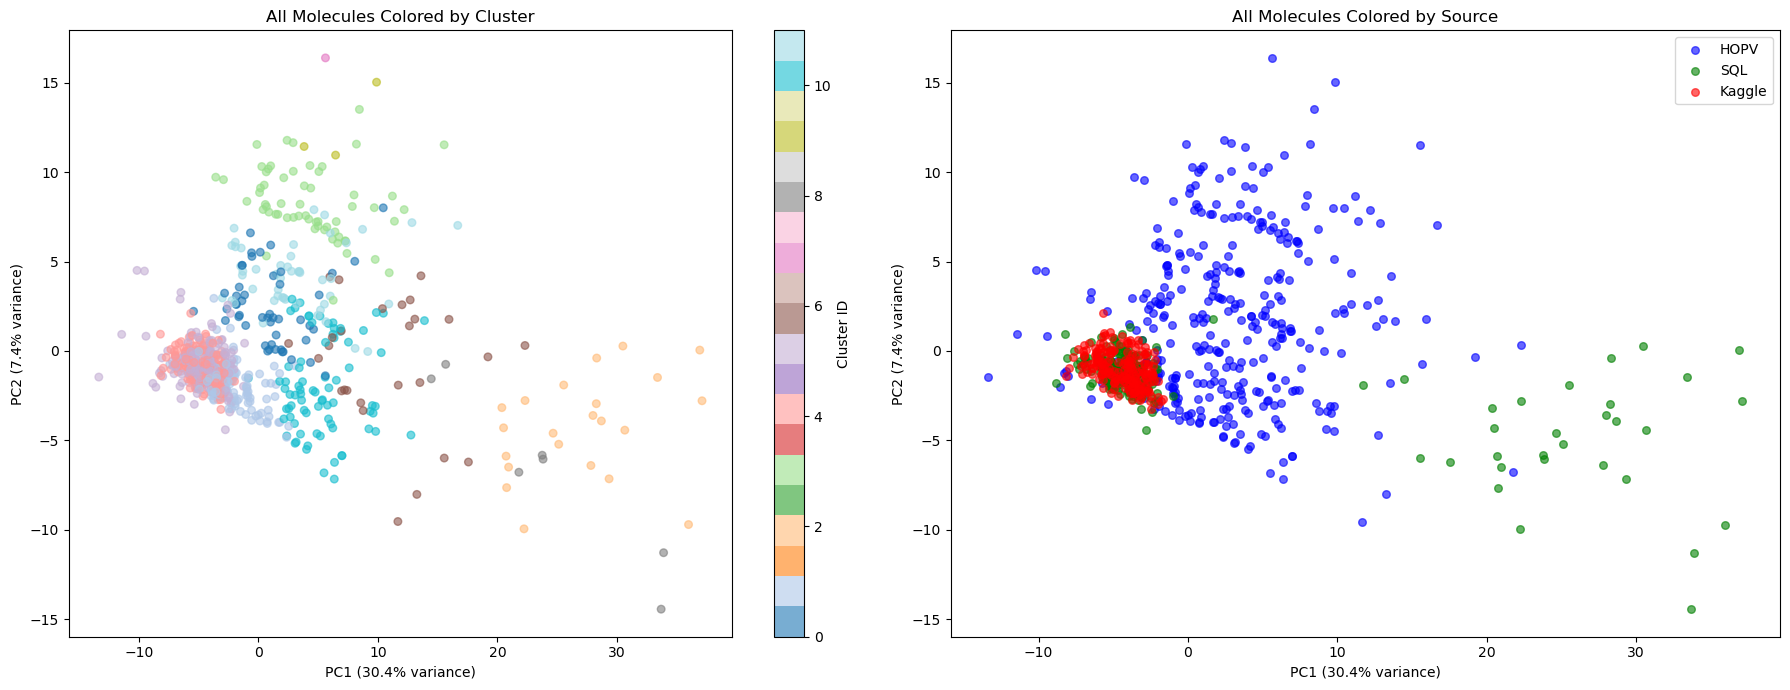

In [10]:
# PCA for visualization
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

# Plot by cluster
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# Plot 1: Colored by cluster
scatter1 = axes[0].scatter(X_pca[:, 0], X_pca[:, 1], 
                          c=cluster_labels, cmap='tab20', 
                          alpha=0.6, s=30)
axes[0].set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.1%} variance)')
axes[0].set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.1%} variance)')
axes[0].set_title('All Molecules Colored by Cluster')
plt.colorbar(scatter1, ax=axes[0], label='Cluster ID')

# Plot 2: Colored by source
source_colors = {'HOPV': 'blue', 'SQL': 'green', 'Kaggle': 'red'}
for source, color in source_colors.items():
    mask = all_molecules_unique['source'] == source
    axes[1].scatter(X_pca[mask, 0], X_pca[mask, 1], 
                   c=color, label=source, alpha=0.6, s=30)
axes[1].set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.1%} variance)')
axes[1].set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.1%} variance)')
axes[1].set_title('All Molecules Colored by Source')
axes[1].legend()

plt.tight_layout()
plt.show()

## 8. Identify Cross-Dataset Clusters

Find clusters that contain BOTH Kaggle molecules AND HOPV/SQL molecules

In [11]:
if HAS_KAGGLE:
    # Analyze cluster composition
    cluster_composition = all_molecules_unique.groupby(['cluster_id', 'source']).size().unstack(fill_value=0)
    print("Cluster Composition:")
    print(cluster_composition)

    # Identify clusters with Kaggle molecules
    clusters_with_kaggle = cluster_composition[cluster_composition['Kaggle'] > 0].index.tolist()
    print(f"\nClusters containing Kaggle molecules: {clusters_with_kaggle}")
    print(f"Number of such clusters: {len(clusters_with_kaggle)}")
else:
    print('Skipped: needs the Kaggle test molecules')

Cluster Composition:
source      HOPV  Kaggle  SQL
cluster_id                   
0             48       0    1
1             55      37   30
2              0       0   22
3             60       0    0
4              0      85   62
5             28      78  109
6             24       0    3
7              1       0    0
8              2       0    5
9              3       0    0
10            78       0    0
11            48       0    0

Clusters containing Kaggle molecules: [1, 4, 5]
Number of such clusters: 3


## 9. Mark Kaggle-Similar Molecules

In [12]:
if HAS_KAGGLE:
    # Create is_kaggle_similar column
    # A molecule is "Kaggle-similar" if:
    # 1. It's from HOPV or SQL (not Kaggle itself)
    # 2. It's in a cluster that contains at least one Kaggle molecule

    def is_similar_to_kaggle(row):
        # Kaggle molecules themselves are not marked as similar
        if row['source'] == 'Kaggle':
            return False
        # HOPV/SQL molecules in clusters with Kaggle molecules are similar
        return row['cluster_id'] in clusters_with_kaggle

    all_molecules_unique['is_kaggle_similar'] = all_molecules_unique.apply(is_similar_to_kaggle, axis=1)

    # Statistics
    print(f"\nKaggle Similarity Statistics:")
    print(f"Total molecules: {len(all_molecules_unique)}")
    print(f"Kaggle molecules: {sum(all_molecules_unique['source'] == 'Kaggle')}")
    print(f"HOPV/SQL similar to Kaggle: {sum(all_molecules_unique['is_kaggle_similar'])}")
    print(f"HOPV/SQL not similar to Kaggle: {sum((all_molecules_unique['source'] != 'Kaggle') & ~all_molecules_unique['is_kaggle_similar'])}")
else:
    print('Skipped: needs the Kaggle test molecules')


Kaggle Similarity Statistics:
Total molecules: 779
Kaggle molecules: 200
HOPV/SQL similar to Kaggle: 284
HOPV/SQL not similar to Kaggle: 295


In [13]:
if HAS_KAGGLE:
    # Breakdown by source
    similarity_breakdown = all_molecules_unique.groupby('source')['is_kaggle_similar'].value_counts()
    print(f"\nBreakdown by source:")
    print(similarity_breakdown)
else:
    print('Skipped: needs the Kaggle test molecules')


Breakdown by source:
source  is_kaggle_similar
HOPV    False                264
        True                  83
Kaggle  False                200
SQL     True                 201
        False                 31
Name: count, dtype: int64


## 10. Visualize Kaggle Similarity

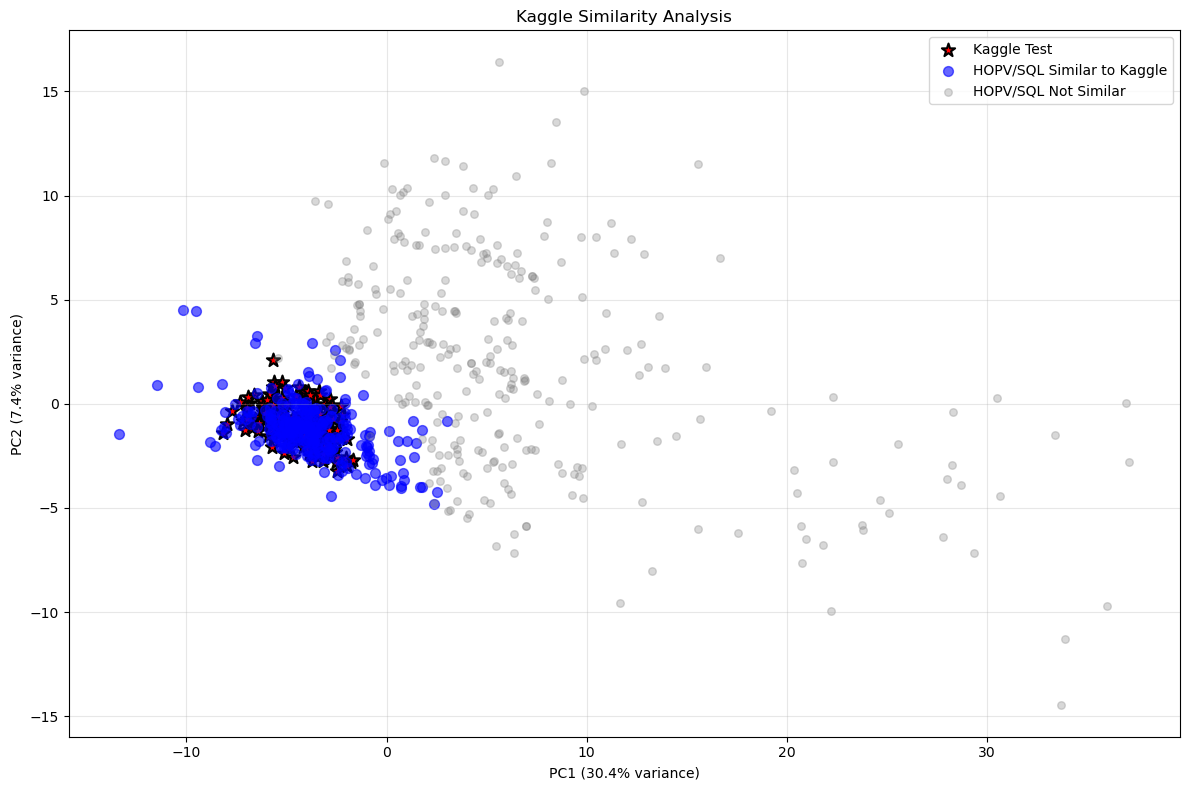

In [14]:
if HAS_KAGGLE:
    # Create visualization
    plt.figure(figsize=(12, 8))

    # Plot Kaggle molecules in red
    kaggle_mask = all_molecules_unique['source'] == 'Kaggle'
    plt.scatter(X_pca[kaggle_mask, 0], X_pca[kaggle_mask, 1], 
               c='red', label='Kaggle Test', s=100, marker='*', edgecolors='black', linewidths=1.5)

    # Plot similar molecules in blue
    similar_mask = all_molecules_unique['is_kaggle_similar']
    plt.scatter(X_pca[similar_mask, 0], X_pca[similar_mask, 1], 
               c='blue', label='HOPV/SQL Similar to Kaggle', s=50, alpha=0.6)

    # Plot non-similar molecules in gray
    not_similar_mask = (all_molecules_unique['source'] != 'Kaggle') & ~all_molecules_unique['is_kaggle_similar']
    plt.scatter(X_pca[not_similar_mask, 0], X_pca[not_similar_mask, 1], 
               c='gray', label='HOPV/SQL Not Similar', s=30, alpha=0.3)

    plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.1%} variance)')
    plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.1%} variance)')
    plt.title('Kaggle Similarity Analysis')
    plt.legend(loc='best')
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()
else:
    print('Skipped: needs the Kaggle test molecules')

## 11. Export Results to CSV

In [15]:
# Create final output dataframe
# Save to CSV
cols = ['smiles', 'source', 'cluster_id'] + (['is_kaggle_similar'] if HAS_KAGGLE else [])
output_df = all_molecules_unique[cols].copy()
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
output_df.to_csv(PROCESSED_DIR / 'cluster_assignments.csv', index=False)

print(f"\n✓ Saved data/processed/cluster_assignments.csv")
print(f"  Shape: {output_df.shape}")
print(f"  Columns: {output_df.columns.tolist()}")
print(f"\nFirst 10 rows:")
print(output_df.head(10))


✓ Saved kaggle_similarity.csv
  Shape: (779, 3)
  Columns: ['smiles', 'cluster_id', 'is_kaggle_similar']

First 10 rows:
                                              smiles  cluster_id  \
0  Cc1ccc(-c2c3cc(-c4ccc(-c5sc(-c6cccs6)c6cc(S(C)...          10   
1    CN1c2ccccc2C(=C2c3ccc(-c4cccs4)cc3N(C)C2=O)C1=O          11   
2  Cc1cc(-c2cc3c4nsnc4c(-c4cc(C)c(-c5cccs5)s4)cc3...           1   
3  Cn1c2ccccc2c2ccc(-c3ccc(-c4ccc(C5=C(c6ccccc6)C...          10   
4  Cc1cc(-c2c3cc(-c4cccs4)sc3c(-c3cc(C)c(C)s3)c3c...          11   
5  C#Cc1cc(OC)c(C#Cc2scc3nc(-c4ccccc4)c(-c4ccccc4...           0   
6  Cc1csc(-c2ccc(-c3cc(C)c(-c4cc5c(s4)c(-c4ccc(C)...          10   
7  CC1=CC(c2cc(C)c(-c3ccc(-c4sc(-c5nc(C)c(-c6cccs...           1   
8  CN1C(=O)C2=C(c3ccc(-c4ccc(C(F)(F)F)cc4)s3)N(C)...          11   
9  CC1(C)c2ccccc2-c2ccc(N(c3ccc(-c4ccc(-c5ccc(C=C...           3   

   is_kaggle_similar  
0              False  
1              False  
2               True  
3              False  
4             

## 12. Summary and Recommendations

### Key Findings:

1. **Total molecules analyzed:** 779 unique molecules
2. **Number of clusters:** 12 clusters
3. **Kaggle-similar training molecules:** 284 of the 579 HOPV/SQL molecules share a cluster with at least one Kaggle test molecule (83 from HOPV, 201 from SQL)
4. The SQL molecules resemble the test set much more closely than HOPV does, which supports adding them to the training data

### Ideas that were not pursued

Weighting Kaggle-similar molecules higher during training, using them as a validation set that better mimics the test set, or adding `cluster_id` as a feature. None of these are used in the final models.